# Tópico 9 - Janelamento e Vazamento Espectral (Spectral Leakage)

## Visão Geral e Objetivos
Neste notebook, investigamos o fenômeno do **Vazamento Espectral (*Spectral Leakage*)** e o uso de **Funções de Janelamento** no processamento digital de sinais. Os objetivos principais são:
1. **Origem do Vazamento Espectral**: Analisar o que ocorre quando a frequência de uma componente senoidal não coincide com um índice inteiro (*bin*) da DFT.
2. **Aplicação de Janelas**: Comparar o desempenho do sinal sem janela adicional (Janela Retangular) em relação às janelas de **Hann** e **Hamming**:
   $$x_w[n] = x[n] \cdot w[n]$$
3. **Trade-off Espectral**: Avaliar o compromisso entre a atenuação dos lóbulos secundários (*side lobes*) e o alargamento do lóbulo principal (*main lobe*).
4. **Gerenciamento de Figuras**: Exportar os gráficos gerados diretamente para o diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Geração do Sinal com Frequência Não-Inteira de Bin

Para evidenciar o vazamento espectral, geramos um sinal senoidal de $f_0 = 105\text{ Hz}$ com taxa de amostragem $f_s = 1000\text{ Hz}$ e $N = 64$ amostras.
- O bin ideal da DFT corresponderia a $k = \frac{f_0 N}{f_s} = \frac{105 \times 64}{1000} = 6,72$.
- Como $k = 6,72$ não é um número inteiro, a descontinuidade nas bordas do bloco de amostragem gera vazamento espectral ao longo de todos os bins.

Abaixo, definimos as janelas **Retangular**, **Hann** e **Hamming**, e aplicamos ao sinal temporal.

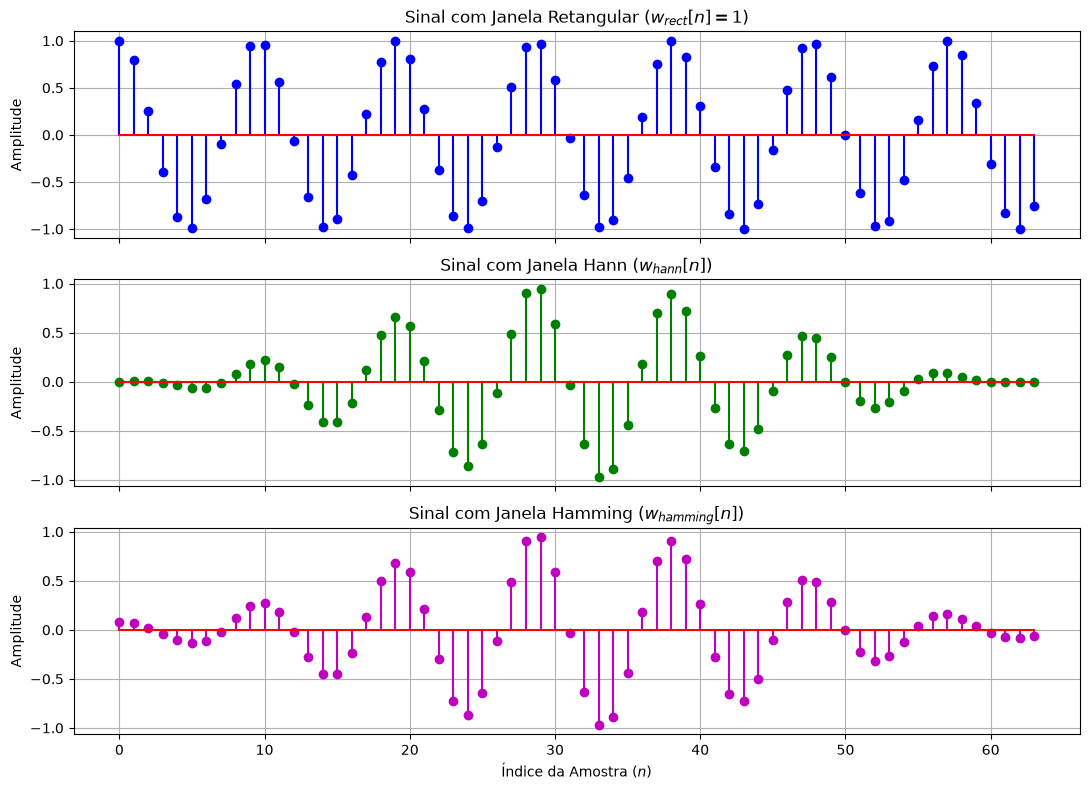

In [2]:
# Parâmetros do sinal
N = 64
fs = 1000.0  # Hz
f0 = 105.0   # Hz (Bin não-inteiro: k = 6.72)

# Vetor temporal discreto
n = np.arange(N)
t = n / fs

# Sinal base
x = np.cos(2 * np.pi * f0 * t)

# Definição das funções de janela
w_rect = np.ones(N)
w_hann = np.hanning(N)
w_hamming = np.hamming(N)

# Aplicação das janelas ao sinal
x_rect = x * w_rect
x_hann = x * w_hann
x_hamming = x * w_hamming

# Plotagem dos sinais janelados no tempo
fig1, axs1 = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axs1[0].stem(n, x_rect, linefmt='b-', markerfmt='bo', basefmt='r-')
axs1[0].set_title(r'Sinal com Janela Retangular ($w_{rect}[n] = 1$)')
axs1[0].set_ylabel('Amplitude')
axs1[0].grid(True)

axs1[1].stem(n, x_hann, linefmt='g-', markerfmt='go', basefmt='r-')
axs1[1].set_title(r'Sinal com Janela Hann ($w_{hann}[n]$)')
axs1[1].set_ylabel('Amplitude')
axs1[1].grid(True)

axs1[2].stem(n, x_hamming, linefmt='m-', markerfmt='mo', basefmt='r-')
axs1[2].set_title(r'Sinal com Janela Hamming ($w_{hamming}[n]$)')
axs1[2].set_xlabel('Índice da Amostra ($n$)')
axs1[2].set_ylabel('Amplitude')
axs1[2].grid(True)

plt.tight_layout()
fig1.savefig("grafico_janelas_tempo.png")
plt.show()

## 2. Análise Espectral Comparativa: Retangular vs. Hann vs. Hamming

Calculamos a FFT de alta densidade (via zero-padding a 1024 pontos para visualização contínua do espectro de magnitude e escala em decibéis $\text{dB}$) para comparar o comportamento espectral das três janelas.

- **Janela Retangular**: Lóbulo principal estreito, mas lóbulos secundários altos (alto vazamento espectral, atenuação do 1º lóbulo $\approx -13\text{ dB}$).
- **Janela Hann**: Lóbulo principal mais largo, porém lóbulos secundários significativamente atenuados (baixo vazamento, atenuação $\approx -32\text{ dB}$).
- **Janela Hamming**: Lóbulo principal mais largo, com excelente atenuação do primeiro lóbulo secundário ($\approx -43\text{ dB}$).

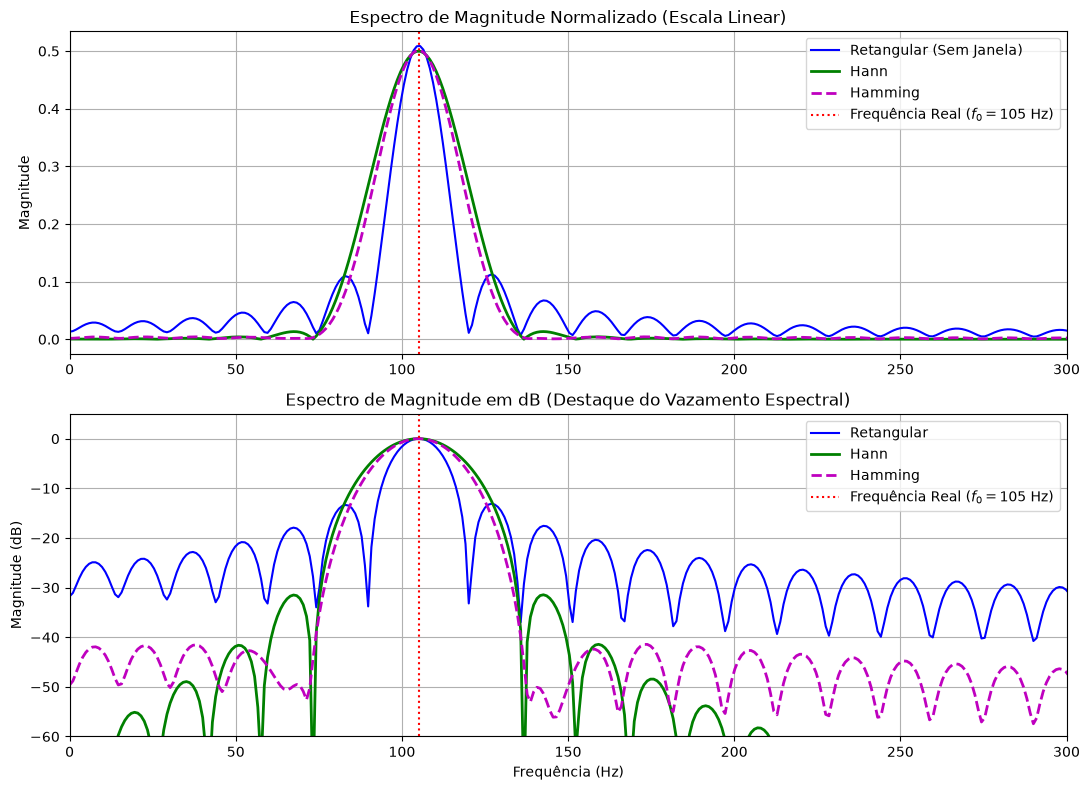

In [3]:
# Zero-padding para alta resolução visual do espectro (N_fft = 1024)
N_fft = 1024
freqs = np.fft.fftfreq(N_fft, d=1/fs)[:N_fft//2]

# Cálculo das FFTs normalizadas pela soma dos pesos da janela
X_rect_fft = np.abs(np.fft.fft(x_rect, N_fft)[:N_fft//2]) / np.sum(w_rect)
X_hann_fft = np.abs(np.fft.fft(x_hann, N_fft)[:N_fft//2]) / np.sum(w_hann)
X_hamming_fft = np.abs(np.fft.fft(x_hamming, N_fft)[:N_fft//2]) / np.sum(w_hamming)

# Conversão para escala logarítmica dB (relativa ao pico)
X_rect_db = 20 * np.log10(np.maximum(X_rect_fft / np.max(X_rect_fft), 1e-4))
X_hann_db = 20 * np.log10(np.maximum(X_hann_fft / np.max(X_hann_fft), 1e-4))
X_hamming_db = 20 * np.log10(np.maximum(X_hamming_fft / np.max(X_hamming_fft), 1e-4))

# Plotagem comparativa dos espectros em dB
fig2, (ax_lin, ax_db) = plt.subplots(2, 1, figsize=(11, 8))

# 1. Escala de Amplitude Normalizada (Linear)
ax_lin.plot(freqs, X_rect_fft, 'b-', linewidth=1.5, label='Retangular (Sem Janela)')
ax_lin.plot(freqs, X_hann_fft, 'g-', linewidth=2.0, label='Hann')
ax_lin.plot(freqs, X_hamming_fft, 'm--', linewidth=2.0, label='Hamming')
ax_lin.axvline(x=f0, color='r', linestyle=':', label=r'Frequência Real ($f_0 = 105\text{ Hz}$)')
ax_lin.set_title('Espectro de Magnitude Normalizado (Escala Linear)')
ax_lin.set_ylabel('Magnitude')
ax_lin.set_xlim(0, 300)
ax_lin.grid(True)
ax_lin.legend(loc='upper right')

# 2. Escala Logarítmica (dB) para destacar o Vazamento nos Lóbulos Laterais
ax_db.plot(freqs, X_rect_db, 'b-', linewidth=1.5, label='Retangular')
ax_db.plot(freqs, X_hann_db, 'g-', linewidth=2.0, label='Hann')
ax_db.plot(freqs, X_hamming_db, 'm--', linewidth=2.0, label='Hamming')
ax_db.axvline(x=f0, color='r', linestyle=':', label=r'Frequência Real ($f_0 = 105\text{ Hz}$)')
ax_db.set_title('Espectro de Magnitude em dB (Destaque do Vazamento Espectral)')
ax_db.set_xlabel('Frequência (Hz)')
ax_db.set_ylabel('Magnitude (dB)')
ax_db.set_xlim(0, 300)
ax_db.set_ylim(-60, 5)
ax_db.grid(True)
ax_db.legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_vazamento_espectral.png")
plt.show()

## 3. Síntese dos Resultados sobre Janelamento
- **Vazamento Espectral**: Ocorre quando a truncagem temporal descontínua espalha a energia de uma frequência única por múltiplos bins adjacentes da DFT.
- **Janela Retangular**: Oferece a maior resolução espectral (lóbulo principal mais estreito), mas apresenta o pior vazamento espectral (lóbulos secundários em torno de $-13\text{ dB}$).
- **Janelas Hann e Hamming**: Suavizam as bordas do sinal no tempo (atenuando as descontinuidades), o que reduz drasticamente o vazamento espectral nos lóbulos secundários, às custas de um discreto alargamento do lóbulo principal (pequena redução na resolução espectral).